w# Practical IA : TP1

## MedMNIST with vectors

In this TP, you will use Deep Learning algorithms in the context of medical images. To do this, you will first work on one of the datasets available in the [MedMNIST](https://medmnist.com/)  database . MedMNIST is a set of biomedical images made up of 12 datasets of 2D images and 6 datasets of 3D images. All images are 28x28 (2D) or 28x28x28 (3D). Larger versions are also available: 64x64 (2D), 128x128 (2D), 224x224 (2D), and 64x64x64 (3D). The various existing machine learning tasks most frequently used in medical imaging are included (binary/multi-class, multi-label and ordinal regression). 

Here, we will focus on the PneumoniaMNIST dataset, mainly because of its size (4708 images in training, 524 in validation and 624 in testing) and we will seek to apply a deep neural network to this dataset.

Some of the code needed to install certain libraries and load the data is provided below, and will serve as a basis for the rest of the TP.

First of all, the libraries we are going to use during this TP are the following. Ensure that all of them are available, and if some are missing you can install them locally for yourself with the following command : !pip install --user "library_name". Different libraries are available in order to develop deep learning models, namely Tensorflow, Keras or PyTorch among few others. In this TP, we are going to use PyTorch for two main reasons : first of all, it is probably the most used in general, allowing you to better understand available codes, and secondly, it is a bit more user friendly, especially compared to Tensorflow. 

You can work on this TP at : [io.ensea.fr](io.ensea.fr), or on you own computer.

In [1]:
import torch
import torchvision
import torchvision.transforms as transforms
import torchvision.datasets as datasets
import torch.nn.functional as F
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset
from torch.utils.data import DataLoader
from tqdm import tqdm
import matplotlib.pyplot as plt
from PIL import Image
import numpy as np

/usr/bin/pip:6: DeprecationWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html
  from pkg_resources import load_entry_point
Using downloaded and verified file: /home/guillaume/.medmnist/pneumoniamnist.npz
Using downloaded and verified file: /home/guillaume/.medmnist/pneumoniamnist.npz
Using downloaded and verified file: /home/guillaume/.medmnist/pneumoniamnist.npz


/home/guillaume/.local/lib/python3.8/site-packages/medmnist/utils.py:32: FutureWarning: `multichannel` is a deprecated argument name for `montage`. It will be removed in version 1.0. Please use `channel_axis` instead.
  montage_arr = skimage_montage(sel_img, multichannel=(n_channels == 3))


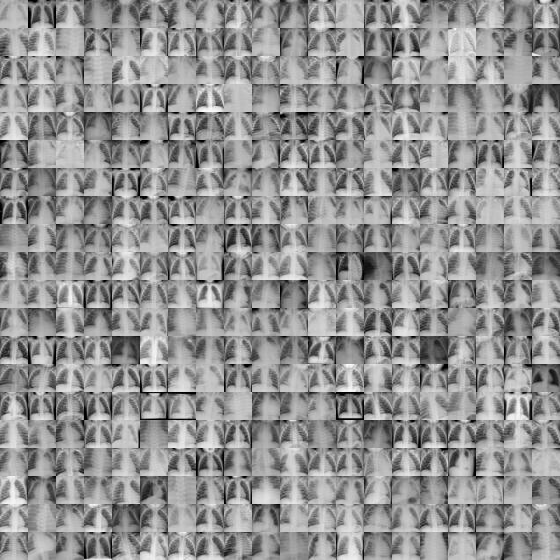

In [2]:
!pip install medmnist
# preprocessing
data_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean=[.5], std=[.5]),
    transforms.Lambda(torch.flatten)
])

from medmnist import PneumoniaMNIST
from medmnist import INFO, Evaluator

dataset_train = PneumoniaMNIST(split="train", transform = data_transform, download=True, size=28)
dataset_valid = PneumoniaMNIST(split="val", transform = data_transform, download=True, size=28)
dataset_test = PneumoniaMNIST(split="test", transform = data_transform, download=True, size=28)

data_flag = 'pneumoniamnist'

info = INFO[data_flag]
task = info['task']
n_channels = info['n_channels']
n_classes = len(info['label'])

dataset_train.montage(20)


### 2: Preparing the data

The code below is used to prepare the DataLoader, which will be used to pass the images through the neural network.

Q3 : What do the variables N and C correspond to? 

In [ ]:
batch_size = 64

train_dataloader = DataLoader(dataset_train, batch_size=batch_size, drop_last=False, shuffle=True)
val_dataloader = DataLoader(dataset_valid, batch_size=batch_size, drop_last=False, shuffle=False)
test_dataloader = DataLoader(dataset_test, batch_size=batch_size, drop_last=False, shuffle=False)

for X, y in train_dataloader:
    print(f"Shape of X [N, C]: {X.shape}")
    print(f"Shape of y: {y.shape} {y.dtype}")

### 3 : Network development and learning

#### Neural networks: 

Now that our data are ready to be processed, we now have to define our deep learning model. For the moment, only one type of neural network is known: the multi-layer perceptron (MLP), which is made up of linear layers followed by activation functions. 

First step consists in defining a new class that inherit from the torch.nn.Module class. For this, we have to define 2 methods : the \_\_init__ method and the forward method. The \_\_init__ method is used to instantiate the different layers of our model (convolutional, activation function or pooling layer for example). In PyTorch, activation function are considered as layers, but in general, it is the combination of activation function with parameteizable linear function that are considered as layers. On the other hand, the forward method use the previously defined layer to compute our model.  

Define both \_\_init__ and forward methods according to the following requirements : 
1. We want 2 Linear layers
2. First Linear layer is followed by a ReLU activation. 
3. Second Linear layer is followed by a Softmax activation
4. First Linear layer is made of 128 hidden units 
5. Second Linear layer is used for decision. Deduce the number of hidden units according to this.

To help you, here are the different function you will need to use : [Module](https://pytorch.org/docs/stable/generated/torch.nn.Module.html),[Linear](https://pytorch.org/docs/stable/generated/torch.nn.Linear.html#torch.nn.Linear), [ReLU](https://pytorch.org/docs/stable/generated/torch.nn.ReLU.html), [Softmax](https://pytorch.org/docs/stable/generated/torch.nn.Softmax.html#softmax)

__A little word about functions named with double underscore as prefixe and suffixe :__ you may have noticed that the functions we defined have a double underscore before and after their name. These methods are called _dunder_ (for double underscore) methods or _magic_ methods. In Python, dunder methods are methods that allow instances of a class to interact with the built-in functions and operators of the language. They are never directly called by the programmer, which is why they are called _magic_. If you are familiar with Java, it is a bit similar to the method toString(). This is also what allow the '+' operator to concatenate two lists, through the dunder method \_\_add__.

In [ ]:
class TinyMLP(nn.Module):
    def __init__(self):
        super(TinyMLP, self).__init__()
        # To fill
        ...
        
    def forward(self,x):
        # To fill
        ...
        return

__Training and validation loop__

Now, we have to define our training and testing process. For this, we decide here to define 2 functions train and test, but this could be done any other way. 

On one side, the train function is designed to optimize the parameters of the model according to the training data and a loss function. For each batch of data, this function compute the prediction of the model, compute a loss by comparing the prediction and the ground truth, and backpropagate this loss.

On the other side, the test function is only here to evaluate our model through a loss function. 

1. Complete the train loop. 
2. Complete the test loop. 

Q4 : What is the fundamental difference between those 2 functions ?

In [ ]:
my_model = TinyMLP()
optimizer = torch.optim.Adam(my_model.parameters(), lr=1e-4)
my_loss = nn.CrossEntropyLoss()
device = "cpu"
my_model.to(device)

loss_train = []
loss_valid = []

for epoch in tqdm(range(100)):
    
    my_model.train() #Used to tell we're training the model
    size = len(train_dataloader.dataset)
    
    loss_total = 0
    for batch, (X, y) in enumerate(train_dataloader):
        X, y = X.to(device), y.squeeze().to(device)
    
        # Compute prediction error
        pred = ...
        loss = ...
        loss_total += loss.item()
        
        # Backpropagation
        loss.backward()
        optimizer.step()
        optimizer.zero_grad()
        
    loss_train.append(loss_total/size)
    
    my_model.eval()
    
    for batch, (X,y) in enumerate(val_dataloader):
        X, y = X.to(device), y.squeeze().to(device)
    
        # Compute prediction error
        #To fill
        ...
        
    loss_valid.append(loss_total/size)
        


__Plotting the training__

By using the matplotlib library, plot both losses (valid and train). 

Q5 : Explain and analyse what you observe on the curve ?

In [ ]:
plt.plot(loss_train)
plt.plot(loss_valid)

__Hyperparameter Tuning__ 

As we saw during the course, there are many different hyperparameters than can tuned : number of layers, number of neurons per layer, learning rate etc... 
Try to modify them and observe their influence on your model.

Q6 : which setting of hyperparameters do you think is the most interesting here ? 

__Evaluating the test dataset__

We now need to evaluate our model. Since we optimized our model using both training and validation datasets, we need to use a new set of data, which we kept as the testing set. It is really important to differentiate these 3 datasets and to not mix them to ensure independence between the model and the evaluated data.

Q7 Evaluate your model by using a correct metric. How do you interpret this metric ?